# 04 · Histology ROI Stacks & Digital Pathology Annotations

Two toolboxes: **`roi_utils.py`** — load/clean/prep a 3D histology image stack (§1–4), and **`annotations_utils.py`** — the digital-pathology polygons on top of it (§5). **Rule throughout: the ROI array is only ever read, never modified** — every helper returns a new array or new records.

## 1. Setup

`from roi_utils import *` pulls in every public function. Specimen for this notebook: **biosample 587, stain IHCS**.

In [1]:
# !wget -q -O roi_utils.py https://raw.githubusercontent.com/24f2007780/colab_export_roi/refs/heads/main/roi_utils.py

import sys
from pathlib import Path
if ".." not in sys.path:
    sys.path.append("..")

# Data directory: notebooks/data or stroke_notebooks/data
DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data") if Path("../data").is_dir() else Path(".")

import importlib, roi_utils
importlib.reload(roi_utils)                     # in case an older copy was already imported this session
from roi_utils import *

# Specimen and stain configuration
BIOSAMPLE_ID = 587
STAIN = "IHCS"


## 2. Load Your ROI Stack

A ROI stack is a 3D `.npy` array already cut from the Zarr pyramid (by the ROI Extractor / "Open in Colab" button) and uploaded to Drive. `load_and_preview_roi(drive_id, return_meta=True)` downloads it, prints shape/dtype/size, and parses what it can from the filename into `meta`. Already have a local file? Use `load_roi("my_roi.npy")` instead — no network needed.

Filename : ROI_587_SE1019_X12000_Y12000_Z117_768x768_L4_axial_IHCS.npy
Shape    : (117, 768, 768, 3)
Dtype    : uint8
Size     : 197.44 MB

Parsed Metadata:
  • Center X                 : 12000
  • Center Y                 : 12000
  • Z / section information  : Section 1019, Z=117
  • Stain                    : IHCS
  • Resolution               : Level 4


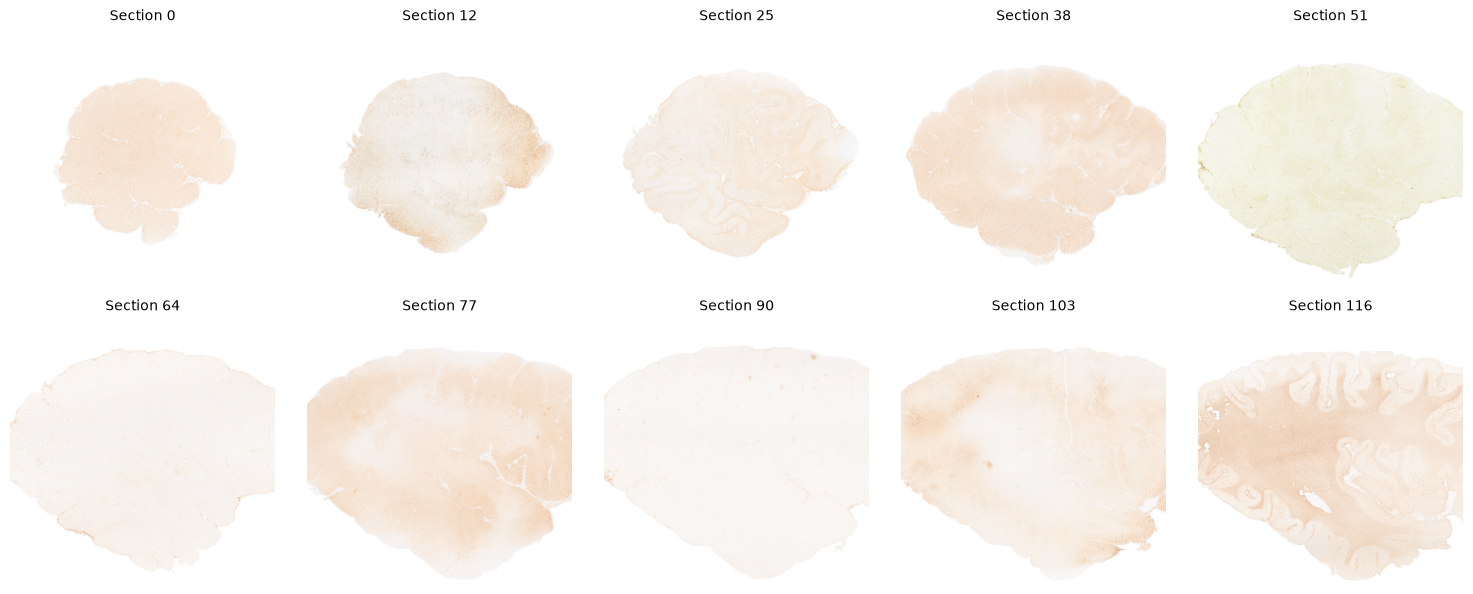

{'filename': 'ROI_587_SE1019_X12000_Y12000_Z117_768x768_L4_axial_IHCS.npy', 'center_section': 1019, 'stain': 'IHCS'}


In [2]:
# PASTE the Google Drive file ID of an ROI stack (e.g. centred on SE1019 for the configured stain):
ROI_DRIVE_ID="1L1_QprfzYrT8v_hhj8LXJJCRq9duIrbQ"
roi, meta = load_and_preview_roi(ROI_DRIVE_ID, return_meta=True)
print(meta)

# Already have a local .npy file? Use this instead:
# roi = load_roi("my_roi.npy")


## 2b. Only Know the Coordinates, Not a Drive ID?

`get_roi_drive_id(biosample_id, section_number, x, y, z, size, stain, resolution)` asks the backend whether this exact ROI was already exported:
- **found** → returns the Drive ID directly (feed it to §2).
- **not found** → extracts nothing; prints a ready-to-open ROI Extractor URL that reproduces it.

(Below we ask about the ROI we just loaded in §2 — it reports "not found," showing a Drive ID and a parameter lookup are two independent paths that don't always agree.)

In [3]:
from roi_utils import get_roi_drive_id

# Same (biosample, section, x, y, z, size, stain, resolution) this ROI's own filename encodes.
drive_id_or_link = get_roi_drive_id(
    biosample_id=BIOSAMPLE_ID,
    section_number=1019,
    x=12000, y=12000, z=117,
    size=768,
    stain=STAIN,
    resolution="4",
)
print("\nget_roi_drive_id returned:", drive_id_or_link)


Not found in Drive yet -- nothing was extracted or uploaded.
Open this ROI Extractor URL to generate it, then use its Drive ID:
http://172.20.23.183:8054/ui/index.html?x=12000&y=12000&z=1019&size=768&zdepth=117&mode=histology&plane=axial&biosample_id=587&stain=IHCS&resolution=4

get_roi_drive_id returned: http://172.20.23.183:8054/ui/index.html?x=12000&y=12000&z=1019&size=768&zdepth=117&mode=histology&plane=axial&biosample_id=587&stain=IHCS&resolution=4


## 3. Explore

`roi_info(roi)` — shape/dtype/size/intensity range. `preview_sections(roi, start=, end=)` — thumbnail grid. Always look before processing.

In [4]:
# Shape, data type, size and intensity statistics
roi_info(roi)

shape     : (117, 768, 768, 3)
dtype     : uint8
size_mb   : 197.44
sections  : 117
min       : 8.0
max       : 255.0
mean      : 241.335769116437
std       : 19.19543835476208
(min/max/mean/std from 20 of 117 sections)


{'shape': (117, 768, 768, 3),
 'dtype': 'uint8',
 'size_mb': 197.44,
 'sections': 117,
 'min': 8.0,
 'max': 255.0,
 'mean': 241.335769116437,
 'std': 19.19543835476208}

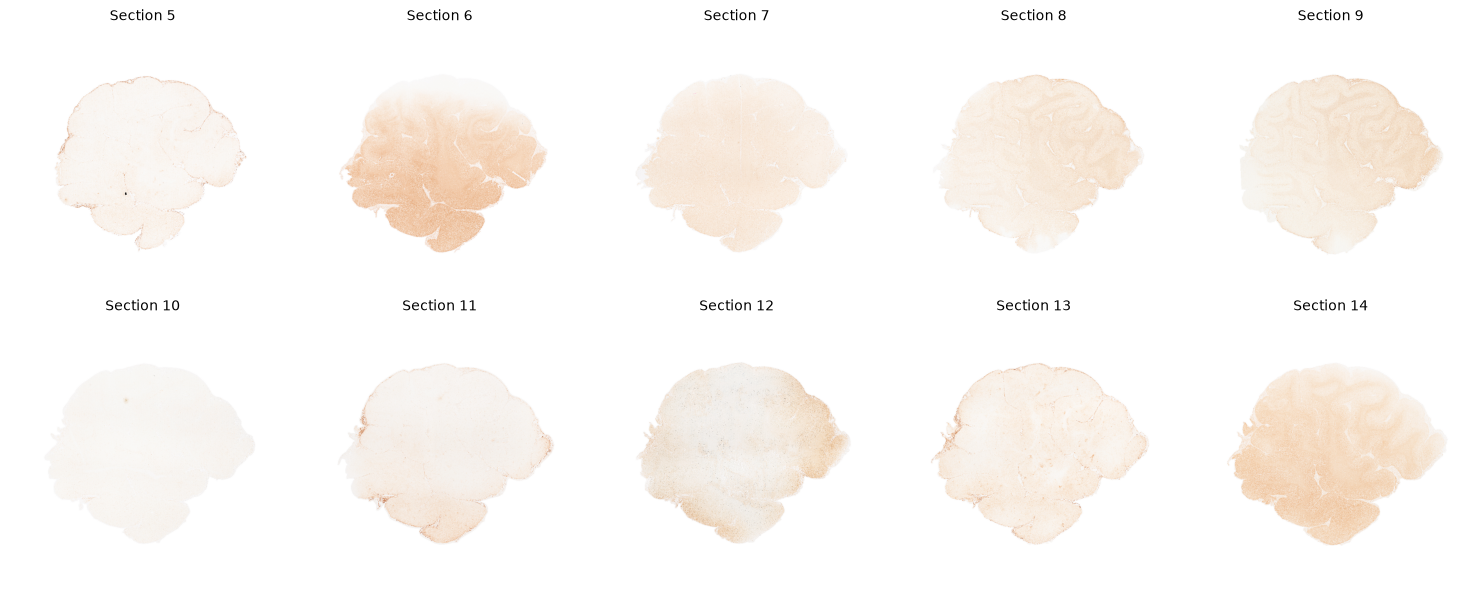

In [5]:
# Preview a range of sections (the end number is not included)
preview_sections(roi, start=5, end=15)

## 4. Prepare for ML

One transform per cell: `get_sections` (sub-stack) → `to_grayscale` → `crop_roi`/`center_crop` (region) → `downsample_roi` → `normalize_roi` → `to_torch`. Each returns a *new* array; `roi` itself is never touched.

In [6]:
# Take a sub-stack of sections 5 to 14
sub = get_sections(roi, 5, 15)
print(sub.shape)

(10, 768, 768, 3)


In [7]:
# Colour (RGB) -> one grayscale channel
gray = to_grayscale(sub)
print(gray.shape)

(10, 768, 768)


In [8]:
# Crop the middle 256 x 256 pixels of every section
cropped = center_crop(gray, 100)
# Or pick exact rows/columns: crop_roi(gray, y=(50, 300), x=(50, 300))
print(cropped.shape)

(10, 100, 100)


### 4b. `crop_roi`: Exact Bounds Instead of a Centred Square

`crop_roi(stack, y=(r0, r1), x=(c0, c1))` — use this instead of `center_crop` when you know the precise region (e.g. from a prior overlay or a model's bounding box).

In [9]:
# Same underlying section stack as above (gray), but an explicit, asymmetric region
# instead of a square centred crop -- e.g. "rows 50-205, columns 20-275".
cropped_explicit = crop_roi(gray, y=(50, 206), x=(20, 276))
print("center_crop shape:", cropped.shape, " crop_roi (explicit bounds) shape:", cropped_explicit.shape)


center_crop shape: (10, 100, 100)  crop_roi (explicit bounds) shape: (10, 156, 256)


In [10]:
# Make each section 2x smaller (averages neighbouring pixels)
small = downsample_roi(cropped, factor=2)
print(small.shape)

(10, 50, 50)


In [11]:
# Scale intensities to 0-1 (clip_percentiles ignores extreme outliers)
# Use method="zscore" for mean 0 / std 1 instead
x = normalize_roi(small, clip_percentiles=(1, 99))
print(x.dtype, x.min(), x.max())

float32 0.0 1.0


In [12]:
# Convert to a PyTorch tensor shaped (sections, channels, height, width)
tensor = to_torch(x)
print(tensor.shape)

torch.Size([10, 1, 50, 50])


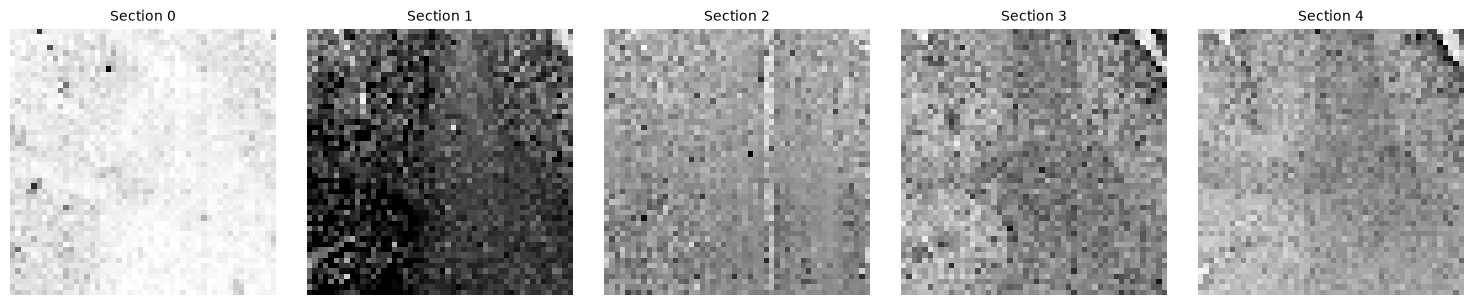

In [13]:
# Quick look at the final result
preview_sections(x, start=0, end=5)

### 4c. Section-Level QC

`section_stats(roi)` computes per-section mean/std/sharpness/background-fraction. `find_section_anomalies(roi)` flags sections that look isolated from *both* neighbours (a likely bad scan); `resolve_atlas_sections` turns those stack indices into real Atlas section numbers. (`flag_sections`/`adjacent_change`/`local_zscore` do similar lower-level checks if you need to dig further — skipped here to keep this brief.)


In [14]:
import pandas as pd
st = section_stats(roi)
df = pd.DataFrame(st)
display(df.describe().T[["min", "50%", "max"]])

,min,50%,max
mean,197.039240,244.279301,251.405628
std,5.160064,10.918133,45.531760
p1,113.666664,215.333328,238.333328
p99,255.000000,255.000000,255.000000
dynamic_range,16.666672,39.666672,141.333336
sharpness,54.379906,411.267975,6377.544434
white_frac,0.308146,0.481394,0.906910
zero_frac,0.000000,0.000000,0.000024
tissue_frac,0.295948,0.602361,0.704766
section,0.000000,58.000000,116.000000


In [15]:
anomalies = find_section_anomalies(roi)
anomaly_df = pd.DataFrame(anomalies)
display(anomaly_df)

,section,d_prev,d_next,d_skip,score
0,115,0.427781,0.615706,0.166782,0.260999


In [16]:
rows = resolve_atlas_sections(
    anomaly_df["section"].tolist(),
    biosample_id=BIOSAMPLE_ID,
    stain=STAIN,
    center_section=meta["center_section"],
    n_sections=len(roi),
)
atlas_df = pd.DataFrame(rows)
display(atlas_df)

stack_index | biosample_id | stain | atlas_section
115         | 587          | IHCS  | 1661


,stack_index,biosample_id,stain,atlas_section,record
0,115,587,IHCS,1661,1661


### 4d. Tissue vs. Background (Fallback)

Most stacks here are already background-removed. `tissue_mask(section)` (optical-density based) and `to_od(section)` are the fallback for sections that still have glass/background in frame.


In [17]:
m = tissue_mask(roi[len(roi) // 2])   # bool (H, W)
od = to_od(roi[len(roi) // 2])        # summed optical density, white ~ 0
print("tissue coverage:", round(float(m.mean()), 3))

tissue coverage: 0.602


## 5. Stroke Histology Annotations

`annotations_utils.py` adds the pathology layer: polygons for CD68 (microglia), GFAP (astrocytes), FIB (fibrin), CD34 (vasculature), HIF1a (hypoxia), served by the c-stroke OpenAtlas API. Pipeline: **load → inspect → visualize → measure → compare → understand.**

In [19]:
# !wget -q -O annotations_utils.py https://raw.githubusercontent.com/24f2007780/colab_export_roi/refs/heads/main/annotations_utils.py

import sys
from pathlib import Path
if ".." not in sys.path:
    sys.path.append("..")

import importlib
import annotations_utils
importlib.reload(annotations_utils)
from annotations_utils import *
import pandas as pd


#### 5.1 Which Proteins Were Annotated Here?

`find_available_annotations(biosample_id, stain, section_num)` — a cheap header-only probe, no polygons downloaded yet.

In [20]:
SECTION = meta["center_section"]      # Atlas section the stack is centred on
available = find_available_annotations(
    biosample_id=BIOSAMPLE_ID,
    stain=STAIN,
    section_num=SECTION,
)
display(pd.DataFrame(available))


/tmp/ipykernel_695325/3905352386.py:2: UserWarning: Availability could not be determined for: FIB (ReadTimeout: HTTPSConnectionPool(host='c-stroke.humanbrain.in', port=443): Read timed out. (read timeout=20))
  available = find_available_annotations(


,protein,description,available,url,status,error
0,CD68,Microglial density (CD68+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
1,GFAP,Astrocyte density (GFAP+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
2,FIB,BBB disruption (Fib+),False,https://c-stroke.humanbrain.in/histology_detec...,NaN,ReadTimeout: HTTPSConnectionPool(host='c-strok...
3,CD34,Vessel density (CD34+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
4,HIF1a,Hypoxic regions (HIF1a+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
5,Nissl,Cell density (Nissl+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
6,H&E,Infarct (H&E),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
7,APP,Axonal injury (APP+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None
8,GAP43,Axonal regrowth (GAP43+),False,https://c-stroke.humanbrain.in/histology_detec...,200.0,None


#### 5.2 Load the Annotations

`load_stroke_annotations(...)` downloads only the proteins §5.1 flagged `available=True` — still in OpenAtlas's own registered coordinate space, not yet ROI pixels.

In [21]:
annotations = load_stroke_annotations(
    biosample_id=BIOSAMPLE_ID,
    stain=STAIN,
    section_num=SECTION,
)
print(len(annotations), "polygons;", sorted({a["protein"] for a in annotations}))
print(annotation_bounds(annotations))   # extent in registered units / implied full-resolution pixels


17 polygons; ['FIB']
{'registered_x': (57015.886163361865, 112106.20578194753), 'registered_y': (-125007.35148899874, -66655.10337096373), 'fullres_px_x': (7126.985770420233, 14013.275722743441), 'fullres_px_y': (8331.887921370466, 15625.918936124843)}


#### 5.3 Overlay on the ROI Section

`to_roi_coordinates(annotations, roi, meta)` reprojects polygons into this ROI's pixel grid and clips to its bounds. `find_stack_index(roi, meta, SECTION)` finds which stack slice matches the Atlas section the annotations belong to.

stack section 58 = Atlas section 1019: 17 of 17 polygons intersect the ROI


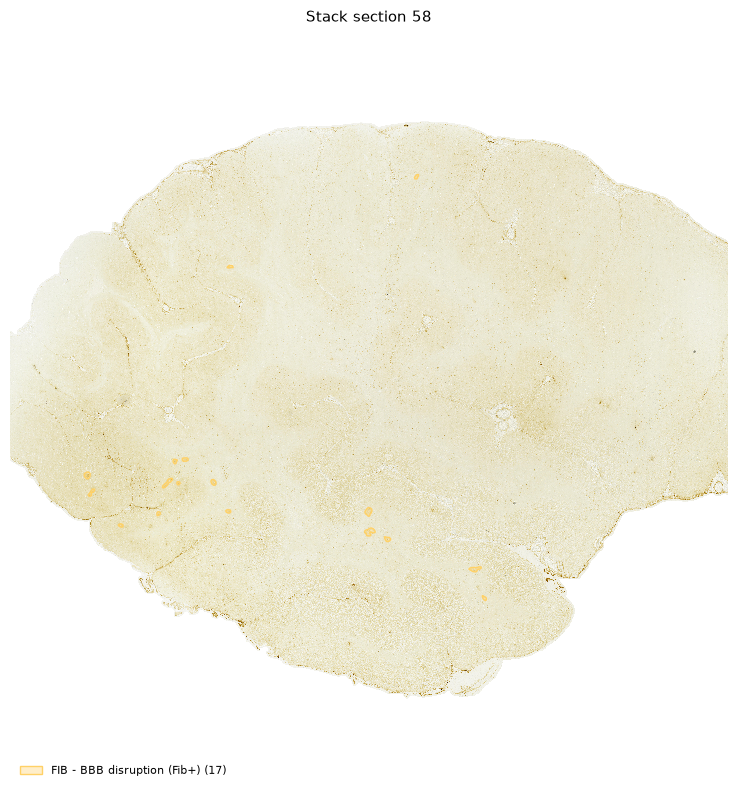

In [22]:
section_index = find_stack_index(roi, meta, SECTION, biosample_id=BIOSAMPLE_ID)
annotations_in_roi = to_roi_coordinates(annotations, roi, meta)   # new records; `annotations` is untouched
print(f"stack section {section_index} = Atlas section {SECTION}:",
      len(annotations_in_roi), "of", len(annotations), "polygons intersect the ROI")
preview_annotations(roi, annotations_in_roi, section_index=section_index)


#### 5.4 The Whole Stack at Once

`load_roi_annotations(roi, meta, biosample_id, stain)` repeats §5.1–5.3 for every slice, returning `roi_annotations[stack_index][protein]` (missing protein → no annotation there, not an error).

In [23]:
roi_annotations = load_roi_annotations(
    roi,
    meta,
    biosample_id=BIOSAMPLE_ID,
    stain=STAIN,
)
# roi_annotations[stack_index]            -> {protein: [records]}
# roi_annotations[stack_index]["FIB"]     -> polygons (a KeyError means that protein does not exist for that section)
sections_with_annotations = [i for i, d in roi_annotations.items() if any(d.values())]
print(f"{len(sections_with_annotations)} of {len(roi_annotations)} stack sections have at least one polygon in the ROI")


ROI 768x768px, origin (level px) = (366, 366), level_factor=16, 8 registered units per full-res px -> 128 units per ROI px, offset=(0, 0) units, y_sign=-1
117 stack sections, 98 with annotation files, 85 with polygons inside the ROI
  CD34   Vessel density (CD34+)      in 22 sections, 676 polygons in the ROI
  GAP43  Axonal regrowth (GAP43+)    in 8 sections, 0 polygons in the ROI
  GFAP   Astrocyte density (GFAP+)   in 18 sections, 3766 polygons in the ROI
  HIF1a  Hypoxic regions (HIF1a+)    in 11 sections, 542 polygons in the ROI
  FIB    BBB disruption (Fib+)       in 21 sections, 294 polygons in the ROI
  CD68   Microglial density (CD68+)  in 18 sections, 543 polygons in the ROI
85 of 117 stack sections have at least one polygon in the ROI


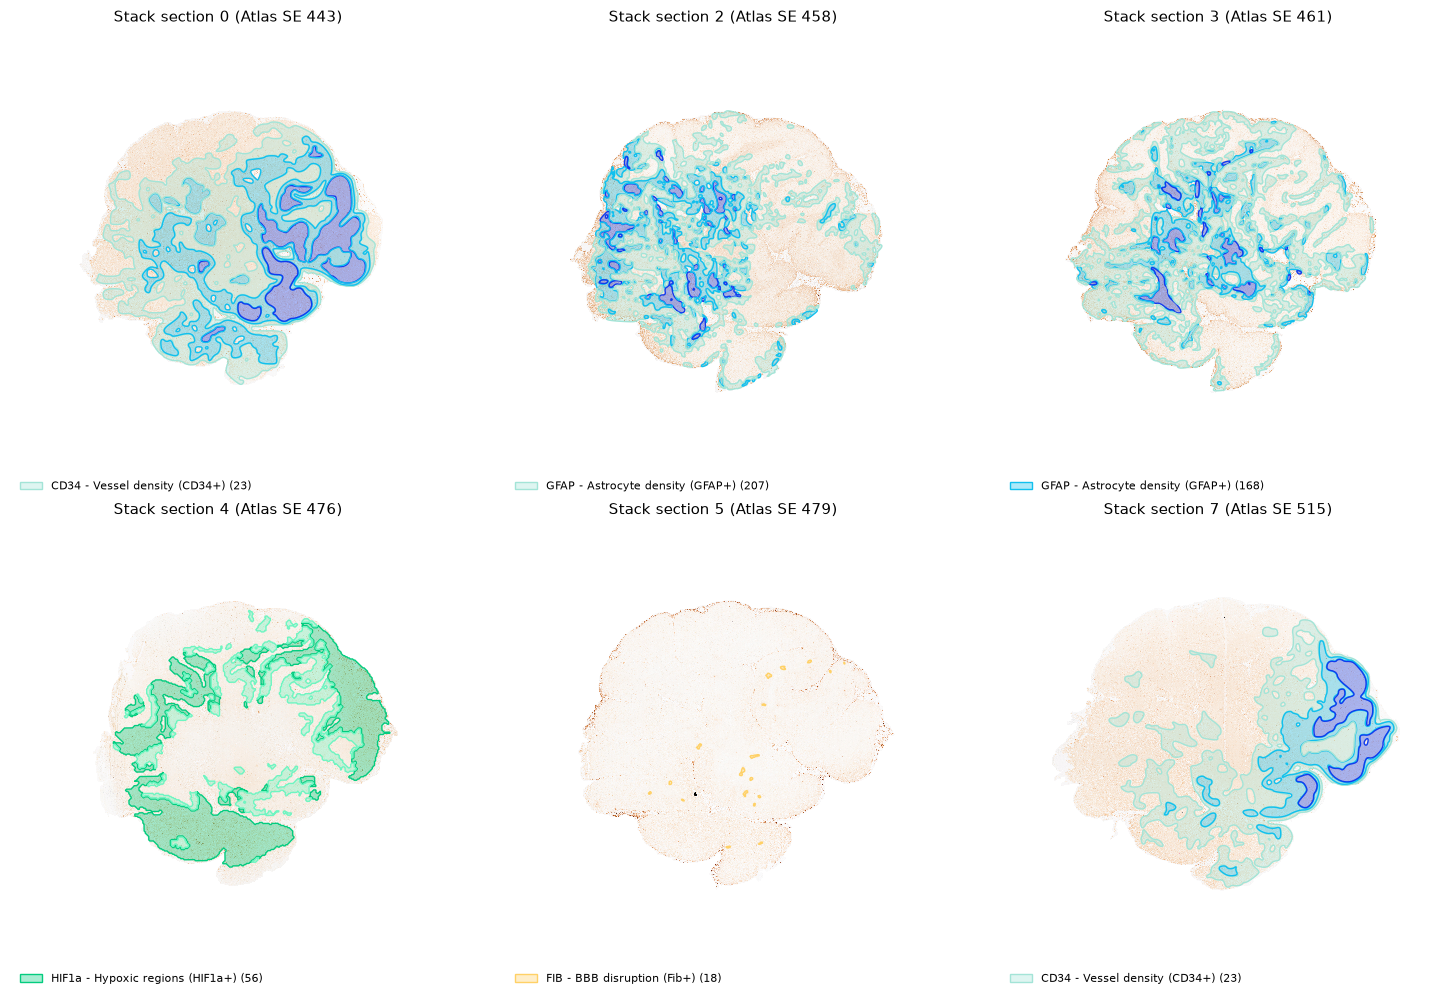

In [24]:
# Gallery of other annotated sections across the stack (section_index was already inspected above)
import matplotlib.pyplot as plt

other_sections = [i for i in sections_with_annotations if i != section_index]
if other_sections:
    preview_idx = other_sections[:6]
    ncols = min(len(preview_idx), 3)
    nrows = (len(preview_idx) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)
    for i, ax in zip(preview_idx, axes.ravel()):
        preview_annotations(roi, roi_annotations, section_index=i, ax=ax, show=False)
    for ax in axes.ravel()[len(preview_idx):]:
        ax.axis("off")
    fig.tight_layout()
    plt.show()
elif sections_with_annotations:
    print(f"Stack section {section_index} is the only section with annotations in this ROI (previewed above in §5.3).")
else:
    print("No sections in this ROI stack have annotations inside the ROI.")


#### 5.5 Morphology

`compute_annotation_properties(records, roi=, section_index=)` turns each polygon into shape descriptors: **area, perimeter, circularity** (1.0 = circle, lower = irregular/branching), **aspect ratio**, **orientation**, **max width**, **tissue coverage**.

In [26]:
# Compute morphological properties for the annotations in our ROI
props = compute_annotation_properties(annotations_in_roi, roi=roi, section_index=section_index)
df_props = pd.DataFrame(props)

cols = ["protein", "feature_id", "class_name", "area", "perimeter", "circularity", "aspect_ratio", "max_width", "tissue_coverage"]
if not df_props.empty:
    display(df_props[[c for c in cols if c in df_props.columns]])
else:
    print(f"No annotations in ROI for section {section_index} to compute properties.")


,protein,feature_id,class_name,area,perimeter,circularity,aspect_ratio,max_width,tissue_coverage
0,FIB,4399,blood brain barrier disruption,19.170314,16.619429,0.872182,1.742083,3.596804,0.000054
1,FIB,2310,blood brain barrier disruption,24.111246,18.083740,0.926516,1.419664,4.588646,0.000068
2,FIB,2524,blood brain barrier disruption,14.820010,14.312582,0.909122,1.451820,3.536213,0.000042
3,FIB,3999,blood brain barrier disruption,12.282680,15.409997,0.649977,2.314230,2.645518,0.000035
4,FIB,1044,blood brain barrier disruption,55.685692,35.218129,0.564184,1.336333,4.577475,0.000157
5,FIB,585,blood brain barrier disruption,46.047341,25.856115,0.865541,1.281054,6.264787,0.000130
6,FIB,1304,blood brain barrier disruption,23.494152,18.800598,0.835269,1.416481,4.368684,0.000066
7,FIB,1792,blood brain barrier disruption,41.567488,30.813319,0.550157,2.589420,4.668557,0.000117
8,FIB,2032,blood brain barrier disruption,13.167925,14.783558,0.757128,1.864315,3.064776,0.000037
9,FIB,5016,blood brain barrier disruption,13.654775,14.596864,0.805333,1.939715,3.042967,0.000038


*Units*: default `units="roi_px"` is **not** physical — pass `units="um"`/`"mm"` with `mpp` (your own scanner/level calibration) for real-world sizes; never guessed automatically.

**Try it**: compact lesions → circularity near 1.0; elongated/branching ones → lower circularity, higher aspect ratio.

In [27]:
# `mpp` must come from YOUR scanner/pyramid calibration (microns per pixel AT THIS ROI LEVEL):
#   mpp_this_level = mpp_level0 * T.level_factor      (T = make_roi_transform(roi, meta))
# No such calibration is recorded anywhere in this pipeline, so a number is never guessed here —
# fill in MPP_THIS_LEVEL yourself before trusting any physical-unit result.
MPP_THIS_LEVEL = None   # e.g. 0.5 * make_roi_transform(roi, meta).level_factor

if MPP_THIS_LEVEL and annotations_in_roi:
    props_um = compute_annotation_properties(annotations_in_roi, units="um", mpp=MPP_THIS_LEVEL)
    df_um = pd.DataFrame(props_um)
    total_area_mm2 = df_um["area"].sum() / 1e6 if "area" in df_um.columns else 0.0
    print(f"Total lesion area: {total_area_mm2:.2f} mm² across {len(df_um)} detections")
elif not annotations_in_roi:
    print("No annotations in ROI to convert to physical units.")
else:
    print("Set MPP_THIS_LEVEL to your scanner calibration to see physical-unit areas.")


Set MPP_THIS_LEVEL to your scanner calibration to see physical-unit areas.


#### Comparing Proteins Across the Stack

`roi_annotations.records()` flattens every polygon from every section/protein; grouping by protein answers *"which pathology is most extensive here?"*

In [28]:
all_props = compute_annotation_properties(roi_annotations.records())
df_all = pd.DataFrame(all_props)

if not df_all.empty and "protein" in df_all.columns:
    protein_summary = df_all.groupby("protein").agg(
        n_polygons=("area", "size"),
        n_sections=("section", "nunique"),
        mean_area=("area", "mean"),
        median_circularity=("circularity", "median"),
        mean_aspect_ratio=("aspect_ratio", "mean"),
        total_area=("area", "sum"),
    ).round(2).sort_values("total_area", ascending=False)
    display(protein_summary)
else:
    print("No annotations found across the ROI stack to summarize.")


,n_polygons,n_sections,mean_area,median_circularity,mean_aspect_ratio,total_area
protein,,,,,,
CD34,676,22,4122.81,0.44,1.86,2787021.54
GFAP,3766,18,519.23,0.64,2.04,1955425.95
CD68,543,18,3140.75,0.56,2.23,1705428.38
HIF1a,542,11,1414.28,0.36,2.21,766540.28
FIB,294,16,310.15,0.76,1.96,91184.36


#### 5.6 Filtering Out Noise

`filter_annotations(records, min_area=, proteins=, acronyms=, feature_ids=)` — e.g. drop anything smaller than the median area to separate likely lesions from debris.

Retained 9 of 17 annotations with area >= 19.2 ROI px²


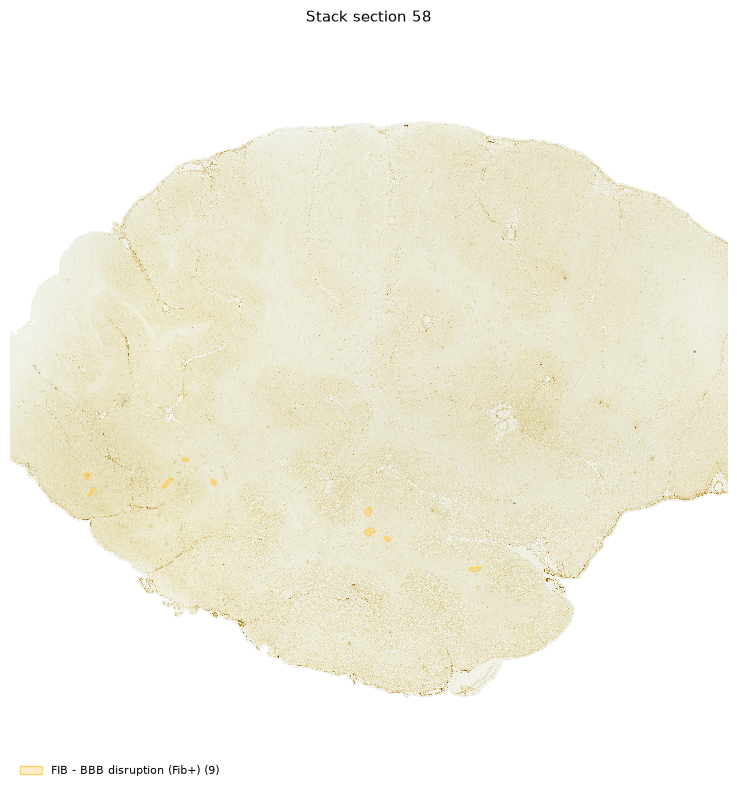

In [29]:
# Keep only the larger lesions (small fragments are often noise/debris).
if not df_props.empty and "area" in df_props.columns and len(annotations_in_roi) > 0:
    AREA_THRESHOLD = float(df_props["area"].median())
    large_lesions = filter_annotations(annotations_in_roi, min_area=AREA_THRESHOLD)
    print(f"Retained {len(large_lesions)} of {len(annotations_in_roi)} annotations with area >= {AREA_THRESHOLD:.1f} ROI px²")
    preview_annotations(roi, large_lesions, section_index=section_index)
else:
    large_lesions = []
    print("No annotations on this section to filter.")


#### 5.7 QC: Is This Actually on Tissue?

`validate_roi_annotations(roi, annotations, section_index, min_tissue_fraction=0.5)` checks each polygon against `tissue_mask` and flags low-overlap detections (possible glass/tear artifacts).

In [30]:
# Check whether annotations sit on real tissue (flagging any with < 50% tissue overlap)
qc = validate_roi_annotations(roi, annotations_in_roi, section_index=section_index, min_tissue_fraction=0.5)

print("Validation summary:", qc["summary"])
qc_df = pd.DataFrame(qc["details"])
cols = ["protein", "feature_id", "tissue_fraction", "valid"]
if not qc_df.empty:
    display(qc_df[[c for c in cols if c in qc_df.columns]])


Validation summary: {'total': 17, 'valid_count': 17, 'flagged_count': 0, 'valid_rate': 1.0, 'min_tissue_fraction': 0.5}


,protein,feature_id,tissue_fraction,valid
0,FIB,4399,1.0,True
1,FIB,2310,1.0,True
2,FIB,2524,1.0,True
3,FIB,3999,1.0,True
4,FIB,1044,1.0,True
5,FIB,585,1.0,True
6,FIB,1304,1.0,True
7,FIB,1792,1.0,True
8,FIB,2032,1.0,True
9,FIB,5016,1.0,True


**Try it**: if anything is flagged, preview it — does it sit on a tissue tear or scan artifact?

#### 5.8 Do Two Proteins Co-Localize?

`compute_annotation_overlap(records_a, records_b, mode="dice"|"iou")` — e.g. does GFAP sit on the same pixels as CD68, or elsewhere? Needs a section with both proteins annotated (found automatically below).

In [31]:
# Find a stack section where at least two different proteins have polygons inside the ROI
candidates = [(i, [p for p, rs in roi_annotations[i].items() if rs]) for i in sections_with_annotations]
multi = [(i, ps) for i, ps in candidates if len(ps) >= 2]

if multi:
    co_section, co_proteins = multi[0]
    p1, p2 = co_proteins[:2]
    set_a, set_b = roi_annotations[co_section][p1], roi_annotations[co_section][p2]
    dice = compute_annotation_overlap(set_a, set_b, mode="dice")
    iou = compute_annotation_overlap(set_a, set_b, mode="iou")
    print(f"Stack section {co_section}: {p1} ({len(set_a)} polygons) vs {p2} ({len(set_b)} polygons) "
          f"-> Dice = {dice:.3f}, IoU = {iou:.3f}")
    preview_annotations(roi, roi_annotations, section_index=co_section, proteins=[p1, p2])
else:
    print("No stack section in this ROI has 2+ proteins annotated; co-localization needs a multi-stain section.")

No stack section in this ROI has 2+ proteins annotated; co-localization needs a multi-stain section.


#### 5.9 ROI Pixel → Original Slide Coordinate

`RoiTransform.invert(roi_xy)` maps a ROI pixel back to the original registered (level-0) coordinate — the inverse of §5.3's projection. Demonstrated on the largest lesion from §5.6, with a round-trip check.

In [32]:
# Locate the largest lesion centroid back in the original registered (level-0) space
T = make_roi_transform(roi, meta)
target_records = large_lesions if large_lesions else annotations_in_roi
lesion_props = compute_annotation_properties(target_records) if target_records else []

if lesion_props:
    biggest = max(lesion_props, key=lambda p: p["area"])
    roi_xy = biggest["centroid"]
    registered_xy = T.invert(roi_xy)
    print(f"Largest lesion ({biggest['protein']} #{biggest['feature_id']}, area={biggest['area']:.1f} ROI px²):")
    print(f"  ROI pixel {tuple(round(v, 1) for v in roi_xy)} -> registered (X, Y) = {tuple(registered_xy.round(1))}")
    print(f"  round-trip check: {T.apply(registered_xy).round(2)}")
else:
    roi_center = [roi.shape[2] // 2, roi.shape[1] // 2]
    registered_xy = T.invert(roi_center)
    print(f"No lesions in ROI to invert; demonstrating on ROI center pixel {roi_center}:")
    print(f"  ROI pixel {roi_center} -> registered (X, Y) = {tuple(registered_xy.round(1))}")
    print(f"  round-trip check: {T.apply(registered_xy).round(2)}")


Largest lesion (FIB #1044, area=55.7 ROI px²):
  ROI pixel (384.8, 536.9) -> registered (X, Y) = (np.float64(96107.3), np.float64(-115571.3))
  round-trip check: [384.84 536.9 ]


#### 5.10 Polygons → 3D Volume

`create_stack_annotation_masks(roi, roi_annotations)` rasterizes every section's polygons into a `(Z, H, W)` boolean volume per protein — for volumetric quantification or lining up against 3D MRI.

**Next**: Notebook 05 plugs this histology layer directly into the MRI lesion segmentation from notebooks 01–03.

In [33]:
# Build 3D boolean volumes matching the entire ROI stack dimensions
stack_masks = create_stack_annotation_masks(roi, roi_annotations)

if stack_masks:
    for protein, mask_3d in stack_masks.items():
        annotated_sections = np.where(mask_3d.any(axis=(1, 2)))[0]
        total_voxels = np.count_nonzero(mask_3d)
        print(f"{protein:<6}: volume shape {mask_3d.shape}, active stack sections: {annotated_sections.tolist()}, total positive pixels: {total_voxels}")
else:
    print("No annotation masks created (no annotations found inside this ROI stack).")


CD34  : volume shape (117, 768, 768), active stack sections: [0, 7, 20, 34, 38, 42, 50, 57, 66, 67, 70, 73, 75, 77, 80, 87, 88, 93, 97, 102, 106, 111], total positive pixels: 2530174
GFAP  : volume shape (117, 768, 768), active stack sections: [2, 3, 8, 9, 24, 25, 26, 40, 43, 54, 56, 60, 76, 85, 91, 110, 113, 116], total positive pixels: 1897653
HIF1a : volume shape (117, 768, 768), active stack sections: [4, 12, 18, 53, 89, 94, 95, 99, 103, 108, 112], total positive pixels: 803365
FIB   : volume shape (117, 768, 768), active stack sections: [5, 11, 13, 19, 22, 23, 41, 45, 51, 58, 69, 71, 74, 82, 100, 115], total positive pixels: 95584
CD68  : volume shape (117, 768, 768), active stack sections: [10, 27, 30, 31, 37, 44, 47, 52, 55, 59, 62, 79, 86, 92, 98, 101, 107, 114], total positive pixels: 1711949
